In [1]:
# ---- Setup: Drive + code + wandb (run this first, every session) ----
REPO_URL = "https://github.com/ammara-asif/fyp.git"   # <-- EDIT ONCE
BRANCH = "nested-b-d"   # the branch with the code this notebook needs (set back to "main" after merging)

import os, subprocess, sys
from google.colab import drive, userdata

# Drive must be mounted from the notebook kernel (never from a !python subprocess).
drive.mount("/content/drive")

# Code: fresh clone each session (Colab disk is wiped on reset), pull if it already exists.
# For a private repo, add a Colab secret GITHUB_TOKEN (a fine-grained read-only token).
CODE = "/content/fyp"
url = REPO_URL
try:
    tok = userdata.get("GITHUB_TOKEN")
    url = REPO_URL.replace("https://", f"https://{tok}@")
except Exception:
    pass
if not os.path.isdir(CODE):
    subprocess.run(["git", "clone", "-q", url, CODE], check=True)
# fetch + checkout + pull, so a clone left on another branch earlier in the session switches over
subprocess.run(["git", "-C", CODE, "fetch", "-q", "origin"], check=True)
subprocess.run(["git", "-C", CODE, "checkout", "-q", BRANCH], check=True)
subprocess.run(["git", "-C", CODE, "pull", "-q", "origin", BRANCH], check=True)
print(BRANCH, subprocess.check_output(["git", "-C", CODE, "log", "-1", "--oneline"]).decode())

# Dependencies (torch/torchvision come preinstalled with Colab's CUDA build; don't reinstall them).
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{CODE}/requirements.txt"], check=True)

# wandb: key comes from the Colab secret WANDB_API_KEY (key icon in the left sidebar). Never hardcode it.
import wandb
wandb.login(key=userdata.get("WANDB_API_KEY"))

sys.path.insert(0, f"{CODE}/src")
# Python caches imported modules for the whole kernel session, so after a git pull
# a plain `import` would silently keep running the OLD code. Drop the cached copies.
_MINE = {"fyp_infra", "stage1_runner", "stage1_analysis", "stage1_drift_diagnostic",
         "stage1_structural", "nested_builder"}
for _m in list(sys.modules):
    if _m in _MINE or _m == "src" or _m.startswith("src."):   # src.* = the team's nested code
        sys.modules.pop(_m, None)
import torch
from fyp_infra import setup_paths, run_sweep, run_id, load_result
import stage1_runner as sr
paths = setup_paths()   # -> /content/drive/MyDrive/fyp_nested_cl/{data,results,logs}
print(paths)
# Hard stop for training: a CPU run is ~12x slower and its timings are useless for budgeting.
REQUIRE_GPU = False   # analysis only: CPU runtime is fine
if REQUIRE_GPU:
    assert torch.cuda.is_available(), "No GPU! Runtime -> Change runtime type -> T4 GPU, then restart."
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU runtime)")

Mounted at /content/drive
nested-b-d fed9369 nested variants



/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ammara-asif125 (kashaf-saleem09-institute-of-business-administration) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


{'root': '/content/drive/MyDrive/fyp_nested_cl', 'data': '/content/drive/MyDrive/fyp_nested_cl/data', 'results': '/content/drive/MyDrive/fyp_nested_cl/results', 'logs': '/content/drive/MyDrive/fyp_nested_cl/logs', 'checkpoints': '/content/drive/MyDrive/fyp_nested_cl/checkpoints'}
GPU: Tesla T4


In [2]:
import stage1_analysis as sa
STAGES = ["stage1_control", "stage1_nested_control", "stage1_epochs_per_task"]   # old control, Flat/B/D via the nested path, steps-per-task test
TRAIN_RUNS = sa.list_runs(paths, stage=STAGES)
for r in TRAIN_RUNS:
    c = r["config"]; print(r["run_id"], sr.arm_label(c), "lr", c["lr"], "seed", c["seed"])
ACFGS = sa.analysis_configs(TRAIN_RUNS)

06a0c117c983 flat_nl lr 0.1 seed 1
07a97dd12ec3 flat_nl lr 0.1 seed 0
1803d732791d llrd_fast_deep lr 0.6 seed 1
32e5df8b8886 flat lr 0.3 seed 2
427e05b19ed5 nested_b lr 0.6 seed 1
48523f3dfeea nested_b lr 0.6 seed 1
4b2bd0082f5c flat lr 0.1 seed 0
585d82e26d13 nested_b lr 0.6 seed 2
59e84252cd1c flat_nl lr 0.1 seed 1
6459881d31c2 nested_b lr 0.6 seed 0
6fa1e584d18e nested_b lr 0.6 seed 0
78e133183087 flat_nl lr 0.1 seed 1
7b3073002436 flat lr 0.3 seed 0
87e47e2a7fd9 flat_nl lr 0.1 seed 0
892486433e6d flat lr 0.1 seed 1
9940a100c076 flat_nl lr 0.1 seed 2
9d5d9fcc4194 llrd_fast_deep lr 0.6 seed 0
b09e3cc29bda flat_nl lr 0.1 seed 2
b2316f2cb5f4 nested_d_lam0.01 lr 0.7 seed 0
b409e8563692 llrd_fast_deep lr 0.6 seed 2
badf7f571542 nested_b lr 0.6 seed 2
bf6b7bf5e853 llrd_slow_deep lr 0.5 seed 2
bf7c7b91a468 llrd_slow_deep lr 0.5 seed 1
c49348e195ec nested_b lr 0.6 seed 2
c4b3004f3b61 nested_d_lam0.01 lr 0.7 seed 2
df55eedeb5e4 nested_b lr 0.6 seed 1
e3344736a804 flat_nl lr 0.1 seed 2
e3be0b

In [3]:
out = run_sweep(ACFGS, sa.analyze_run, paths)

[1/33] 9ec360a4a42b running
  checkpoint 1/20: task-IL on seen tasks 48.2%
  checkpoint 2/20: task-IL on seen tasks 48.0%
  checkpoint 3/20: task-IL on seen tasks 39.7%
  checkpoint 4/20: task-IL on seen tasks 41.7%
  checkpoint 5/20: task-IL on seen tasks 40.6%
  checkpoint 6/20: task-IL on seen tasks 35.5%
  checkpoint 7/20: task-IL on seen tasks 38.9%
  checkpoint 8/20: task-IL on seen tasks 34.6%
  checkpoint 9/20: task-IL on seen tasks 33.5%
  checkpoint 10/20: task-IL on seen tasks 32.4%
  checkpoint 11/20: task-IL on seen tasks 30.3%
  checkpoint 12/20: task-IL on seen tasks 34.5%
  checkpoint 13/20: task-IL on seen tasks 31.9%
  checkpoint 14/20: task-IL on seen tasks 33.0%
  checkpoint 15/20: task-IL on seen tasks 30.5%
  checkpoint 16/20: task-IL on seen tasks 28.9%
  checkpoint 17/20: task-IL on seen tasks 26.0%
  checkpoint 18/20: task-IL on seen tasks 26.6%
  checkpoint 19/20: task-IL on seen tasks 28.8%
  checkpoint 20/20: task-IL on seen tasks 27.8%
[2/33] a9bd34263cd9 a

In [4]:
import numpy as np, pandas as pd
rows = []
for a in ACFGS:
    r = load_result(a, paths)
    if r is None: continue
    m = r["metrics"]; c = m["train_config"]
    row = {"arm": sr.arm_label(c), "lr": c["lr"], "seed": c["seed"],
           "til_final_avg_acc": m["til_final_avg_acc"], "til_avg_forgetting": m["til_avg_forgetting"]}
    for l, name in enumerate(m["level_modules"]):
        row[f"probe_final/{name}"] = m["probe_final_avg"][l]
        row[f"probe_forgetting/{name}"] = m["probe_forgetting"][l]
    rows.append(row)
adf = pd.DataFrame(rows)
display(adf)
summary = adf.drop(columns="seed").groupby(["arm", "lr"]).agg(["mean", "std", "count"])
display(summary.T)

,arm,lr,seed,til_final_avg_acc,til_avg_forgetting,probe_final/layer1,probe_forgetting/layer1,probe_final/layer3,probe_forgetting/layer3,probe_final/layer4,probe_forgetting/layer4
0,flat_nl,0.1,1,27.81,40.673684,65.16,0.105263,71.75,1.652632,70.45,3.747368
1,flat_nl,0.1,0,31.65,52.778947,68.04,1.431579,78.99,6.326316,77.91,8.842105
2,llrd_fast_deep,0.6,1,30.07,54.547368,67.00,1.368421,77.30,6.484211,76.49,10.021053
3,flat,0.3,2,31.70,52.968421,68.07,2.021053,79.45,6.368421,77.89,9.821053
4,nested_b,0.6,1,26.52,42.642105,63.22,1.515789,71.52,2.852632,69.69,5.463158
5,nested_b,0.6,1,29.75,54.610526,66.95,1.126316,77.12,7.073684,75.39,11.800000
6,flat,0.1,0,32.36,52.505263,66.22,2.578947,78.82,5.705263,77.76,8.326316
7,nested_b,0.6,2,29.31,42.273684,67.33,0.284211,76.10,3.421053,74.12,6.336842
8,flat_nl,0.1,1,25.40,48.084211,66.23,1.105263,73.00,4.547368,70.43,6.484211
9,nested_b,0.6,0,31.58,38.189474,65.23,-0.610526,71.51,4.263158,69.62,6.536842


arm                                 flat               flat_nl llrd_fast_deep  \
lr                                   0.1        0.3        0.1            0.6   
til_final_avg_acc       mean   32.213333  33.693333  29.734444      33.046667   
                        std     0.127410   1.894316   3.175811       4.358972   
                        count   3.000000   3.000000   9.000000       3.000000   
til_avg_forgetting      mean   52.792982  51.403509  46.516959      51.778947   
                        std     0.270494   1.703193   7.453751       4.019606   
                        count   3.000000   3.000000   9.000000       3.000000   
probe_final/layer1      mean   68.343333  66.380000  67.362222      67.350000   
                        std     1.839194   1.541850   1.740042       0.888313   
                        count   3.000000   3.000000   9.000000       3.000000   
probe_forgetting/layer1 mean    2.017544   2.014035   0.766082       1.266667   
                        std     0.486645   0.389521   0.695031       0.820535   
                        count   3.000000   3.000000   9.000000       3.000000   
probe_final/layer3      mean   78.823333  78.723333  75.238889      78.726667   
                        std     0.615007   0.720093   3.071272       1.237511   
                        count   3.000000   3.000000   9.000000       3.000000   
probe_forgetting/layer3 mean    5.768421   6.852632   4.112281       5.785965   
                        std     0.623457   0.551302   1.875472       0.878196   
                        count   3.000000   3.000000   9.000000       3.000000   
probe_final/layer4      mean   77.980000  77.733333  73.222222      77.336667   
                        std     0.488672   0.213620   3.462773       0.953799   
                        count   3.000000   3.000000   9.000000       3.000000   
probe_forgetting/layer4 mean    8.364912  10.038596   6.728655       9.515789   
                        std     0.469612   0.306772   2.322865       0.458469   
                        count   3.000000   3.000000   9.000000       3.000000   

arm                           llrd_slow_deep   nested_b nested_d_lam0.01  
lr                                       0.5        0.6              0.7  
til_final_avg_acc       mean       32.696667  30.133333        29.790000  
                        std         3.375816   2.120159         3.046654  
                        count       3.000000   9.000000         3.000000  
til_avg_forgetting      mean       51.785965  45.545029        56.140351  
                        std         3.955225   6.248290         3.246073  
                        count       3.000000   9.000000         3.000000  
probe_final/layer1      mean       68.123333  66.120000        66.416667  
                        std         2.679577   1.363186         1.511500  
                        count       3.000000   9.000000         3.000000  
probe_forgetting/layer1 mean        1.284211   0.591813         1.270175  
                        std         0.934355   0.783447         0.776763  
                        count       3.000000   9.000000         3.000000  
probe_final/layer3      mean       78.533333  75.337778        78.883333  
                        std         1.395075   2.614688         1.680069  
                        count       3.000000   9.000000         3.000000  
probe_forgetting/layer3 mean        6.975439   4.271345         5.270175  
                        std         1.231639   1.647518         1.444306  
                        count       3.000000   9.000000         3.000000  
probe_final/layer4      mean       76.276667  73.600000        76.930000  
                        std         1.436744   2.927811         1.165032  
                        count       3.000000   9.000000         3.000000  
probe_forgetting/layer4 mean       10.021053   7.389474         9.677193  
                        std         1.420819   2.297530         1.176140  
                  

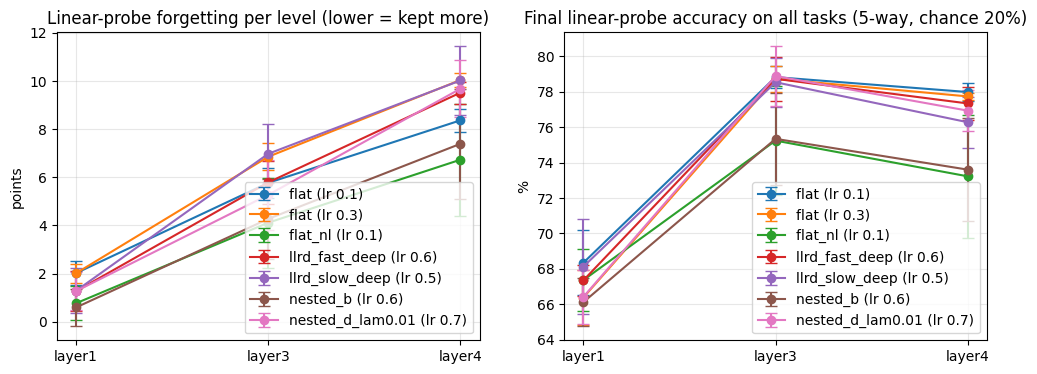

In [5]:
import matplotlib.pyplot as plt
levels = [k.split("/")[1] for k in adf.columns if k.startswith("probe_forgetting/")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (arm, lr), g in adf.groupby(["arm", "lr"]):
    lab = f"{arm} (lr {lr})"
    for ax, key in zip(axes, ["probe_forgetting", "probe_final"]):
        vals = g[[f"{key}/{l}" for l in levels]]
        ax.errorbar(levels, vals.mean(), yerr=vals.std(), marker="o", capsize=4, label=lab)
axes[0].set(title="Linear-probe forgetting per level (lower = kept more)", ylabel="points")
axes[1].set(title="Final linear-probe accuracy on all tasks (5-way, chance 20%)", ylabel="%")
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.show()